# Geometry + Colorimetry Fusion: Pre / Per / Post-Exercise Classification

This notebook combines the two approaches previously tested:
- **Colorimetry** (`colorimetry` notebook): 3 best (non-scene) features (selected based on Random Forest feature importance).
- **Facial Geometry** (`geometric-features` notebook): 3 best features (selected based on Random Forest feature importance).



## 1 - Library

In [71]:
from pathlib import Path

# General and computer vision
import cv2
import mediapipe as mp
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import random

# Machine learning
from sklearn.model_selection import train_test_split
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.dummy import DummyClassifier
from sklearn.metrics import (accuracy_score, balanced_accuracy_score,
                             classification_report, ConfusionMatrixDisplay)

# Statistical analysis
import statsmodels.api as sm
from statsmodels.formula.api import ols

# ---------- Parameters ----------
FOLDER_FEATURES_SELECTION = Path("data/dataset_squat")   # Adapt if needed
FOLDER_TEMPORAL_ANALYSIS = Path("data/dataset_squat_temporal_analysis")   # Adapt if needed
CONDITIONS = ["pre", "per", "post"]
SUBJECTS = ["joel", "theo"]
SEED = 42
random.seed(SEED)
np.random.seed(SEED)
ROI_RATIO = 0.6            # Central face region used for colorimetry
Path("figures").mkdir(exist_ok=True)


## 2 - Features Function

### 2.1 Face Detection (Viola-Jones)

In [53]:
_CASCADE = cv2.CascadeClassifier(cv2.data.haarcascades + "haarcascade_frontalface_default.xml")
if _CASCADE.empty():
    raise RuntimeError("Cascade not loaded: check your OpenCV installation")


def detect_face(img, scale_factor=1.1, min_neighbors=5, min_size=(60, 60)):
    """Input: BGR image. Output: bbox (x, y, w, h) of the largest face, or None."""
    gris = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)
    visages = _CASCADE.detectMultiScale(gris, scaleFactor=scale_factor,
                                        minNeighbors=min_neighbors, minSize=min_size)
    if len(visages) == 0:
        return None
    x, y, w, h = max(visages, key=lambda b: b[2] * b[3])
    return int(x), int(y), int(w), int(h)


def reframe(img, bbox, roi_ratio=1.0):
    """Crop the bounding box (roi_ratio=1.0: full face; 0.6: face center)."""
    x, y, w, h = bbox
    dx, dy = int(w * (1 - roi_ratio) / 2), int(h * (1 - roi_ratio) / 2)
    return img[y + dy : y + h - dy, x + dx : x + w - dx]

### 2.2 Colorimetric features

In [54]:
CANAUX = ("B", "G", "R")   # OpenCV channel order

_niveaux = np.arange(256, dtype=np.float32) / 255.0
_LUT_LIN_U8 = np.where(_niveaux <= 0.04045, _niveaux / 12.92,
                       ((_niveaux + 0.055) / 1.055) ** 2.4).astype(np.float32)

# Ligne Y et somme des lignes X, Y, Z de la matrice sRGB -> XYZ (seul y est nÃƒÂ©cessaire)
_Y_ROW = np.array([0.2126729, 0.7151522, 0.0721750])
_SUM_ROW = np.array([0.4124564 + 0.2126729 + 0.0193339,
                     0.3575761 + 0.7151522 + 0.1191920,
                     0.1804375 + 0.0721750 + 0.9503041])


def _valeur_max(img):
    return float(np.iinfo(img.dtype).max) if np.issubdtype(img.dtype, np.integer) else 1.0


def normaliser(img):
    """BGR image -> float32 in [0, 1] (sRGB values)."""
    return img.astype(np.float32) * np.float32(1.0 / _valeur_max(img))


def srgb_vers_lineaire(img_bgr):
    """BGR image -> linear light float32 in [0, 1]."""
    if img_bgr.dtype == np.uint8:
        return cv2.LUT(img_bgr, _LUT_LIN_U8)
    c = normaliser(img_bgr)
    return np.where(c <= 0.04045, c / 12.92, ((c + 0.055) / 1.055) ** 2.4).astype(np.float32)


def colorimetry(img, bbox, roi_ratio=ROI_RATIO):
    """Input: BGR image + face bounding box. Output: face-center color features."""
    roi = reframe(img, bbox, roi_ratio)
    v_srgb = normaliser(roi)

    v_lin = srgb_vers_lineaire(roi)
    luma = 0.0722 * v_srgb[..., 0] + 0.7152 * v_srgb[..., 1] + 0.2126 * v_srgb[..., 2]
    lum_lin = 0.0722 * v_lin[..., 0] + 0.7152 * v_lin[..., 1] + 0.2126 * v_lin[..., 2]
    luma_flat, lum_lin_flat = luma.ravel(), lum_lin.ravel()
    luma_p1, luma_p99 = np.percentile(luma_flat, [1, 99])
    lum_p1, lum_p99 = np.percentile(lum_lin_flat, [1, 99])
    rgb_lin = v_lin.reshape(-1, 3).mean(axis=0, dtype=np.float64)[::-1]
    xyz_sum = float(_SUM_ROW @ rgb_lin)
    face_x = float((0.4124564 * rgb_lin[0] + 0.3575761 * rgb_lin[1] + 0.1804375 * rgb_lin[2]) / (xyz_sum + 1e-12))
    face_y = float((_Y_ROW @ rgb_lin) / (xyz_sum + 1e-12))
    n = (face_x - 0.3320) / (0.1858 - face_y + 1e-12)
    face_cct = float(np.clip(449 * n**3 + 3525 * n**2 + 6823.3 * n + 5520.33, 1500, 15000))
    return {
        "moyenne_srgb_B": float(v_srgb[..., 0].mean(dtype=np.float64)),
        "moyenne_srgb_G": float(v_srgb[..., 1].mean(dtype=np.float64)),
        "moyenne_srgb_R": float(v_srgb[..., 2].mean(dtype=np.float64)),
        "moyenne_lin_B": float(v_lin[..., 0].mean(dtype=np.float64)),
        "moyenne_lin_G": float(v_lin[..., 1].mean(dtype=np.float64)),
        "moyenne_lin_R": float(v_lin[..., 2].mean(dtype=np.float64)),
        "luma_srgb_moy": float(luma.mean(dtype=np.float64)),
        "luminance_lin_moy": float(lum_lin.mean(dtype=np.float64)),
        "luma_min": float(luma.min()), "luma_max": float(luma.max()),
        "luma_p1": float(luma_p1), "luma_p99": float(luma_p99),
        "etendue_p1_p99": float(luma_p99 - luma_p1),
        "plage_dynamique_stops": float(np.log2((lum_p99 + 1e-4) / (lum_p1 + 1e-4))),
        "contraste_rms": float(luma.std(dtype=np.float64)),
        "contraste_michelson": float((luma_p99 - luma_p1) / (luma_p99 + luma_p1 + 1e-9)),
        "pct_sature": float(100 * np.mean(luma >= 0.98)),
        "pct_sous_expose": float(100 * np.mean(luma <= 0.02)),
        "face_rg": float(rgb_lin[0] / max(rgb_lin[1], 1e-6)),
        "face_bg": float(rgb_lin[2] / max(rgb_lin[1], 1e-6)),
        "face_y": face_y, "face_cct": face_cct,
    }

### 2.3 Geometric features (MediaPipe FaceLandmarker + contours)

In [55]:
def remove_background(visage, iterations=1):
    """Replaces the background of the face crop with its median color (GrabCut)."""
    h, w = visage.shape[:2]
    masque = np.full((h, w), cv2.GC_PR_BGD, dtype=np.uint8)
    bord = max(2, int(min(h, w) * 0.04))
    masque[bord:-bord, bord:-bord] = cv2.GC_PR_FGD
    cv2.ellipse(masque, (w // 2, h // 2), (int(w * 0.42), int(h * 0.48)), 0, 0, 360, cv2.GC_FGD, -1)
    cv2.grabCut(visage, masque, None, np.zeros((1, 65)), np.zeros((1, 65)),
                iterations, cv2.GC_INIT_WITH_MASK)
    avant = np.isin(masque, (cv2.GC_FGD, cv2.GC_PR_FGD)).astype(np.uint8)
    noyau = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (7, 7))
    avant = cv2.morphologyEx(cv2.morphologyEx(avant, cv2.MORPH_CLOSE, noyau), cv2.MORPH_OPEN, noyau)
    pixels_bord = np.concatenate((visage[:bord].reshape(-1, 3), visage[-bord:].reshape(-1, 3)))
    propre = np.broadcast_to(np.median(pixels_bord, axis=0).astype(np.uint8), visage.shape).copy()
    propre[avant > 0] = visage[avant > 0]
    return propre


_MODELE_LANDMARKS = Path("src/models/face_landmarker.task")
_URL_LANDMARKS = ("https://storage.googleapis.com/mediapipe-models/face_landmarker/"
                  "face_landmarker/float16/1/face_landmarker.task")
if not _MODELE_LANDMARKS.exists():
    _MODELE_LANDMARKS.parent.mkdir(parents=True, exist_ok=True)
    urllib.request.urlretrieve(_URL_LANDMARKS, _MODELE_LANDMARKS)
_LANDMARKER = mp.tasks.vision.FaceLandmarker.create_from_options(
    mp.tasks.vision.FaceLandmarkerOptions(
        base_options=mp.tasks.BaseOptions(model_asset_path=str(_MODELE_LANDMARKS)),
        running_mode=mp.tasks.vision.RunningMode.IMAGE, num_faces=1,
        min_face_detection_confidence=0.5, min_face_presence_confidence=0.5))

_GROUPES_LANDMARKS = {
    "oeil_g": [33, 160, 158, 133, 153, 144],
    "oeil_d": [362, 385, 387, 263, 373, 380],
    "bouche_ext": [61, 146, 91, 181, 84, 17, 314, 405, 321, 375, 291, 409, 270, 269, 267, 0, 37, 39, 40],
    "bouche_int": [78, 95, 88, 178, 87, 14, 317, 402, 318, 324, 308, 415, 310, 311, 312, 13, 82, 81],
}


def _points_landmarks(visage):
    rgb = cv2.cvtColor(visage, cv2.COLOR_BGR2RGB)
    res = _LANDMARKER.detect(mp.Image(image_format=mp.ImageFormat.SRGB, data=rgb))
    if not res.face_landmarks:
        return None
    h, w = visage.shape[:2]
    pts = np.array([(l.x * w, l.y * h) for l in res.face_landmarks[0]], dtype=np.float32)
    return pts if np.isfinite(pts).all() else None


def _dist(p, a, b):
    return float(np.linalg.norm(p[a] - p[b]))


def _aire(poly):
    return float(abs(cv2.contourArea(poly.astype(np.float32))))


def _roi_rel(gris, x0, y0, x1, y1):
    h, w = gris.shape[:2]
    return gris[int(h * y0):int(h * y1), int(w * x0):int(w * x1)]


def geometrie(visage):
    """Input: BGR face crop (background removed).
    Output: (dictionary of geometric features, landmarks_ok)."""
    h, w = visage.shape[:2]
    gris = cv2.cvtColor(visage, cv2.COLOR_BGR2GRAY)
    pts = _points_landmarks(visage)
    feats = {}

    if pts is not None:
        inter = max(_dist(pts, 33, 263), 1.0)                       # Interocular distance (normalization)
        lw, rw = _dist(pts, 33, 133) / inter, _dist(pts, 362, 263) / inter
        lh = np.mean([_dist(pts, 160, 144), _dist(pts, 158, 153)]) / inter
        rh = np.mean([_dist(pts, 385, 380), _dist(pts, 387, 373)]) / inter
        bw, bh = _dist(pts, 61, 291) / inter, _dist(pts, 13, 14) / inter
        g = {k: pts[np.asarray(v, dtype=int)] for k, v in _GROUPES_LANDMARKS.items()}
        feats.update({
            "eye_left_opening_ratio": float(lh / max(lw, 1e-6)),
            "eye_right_opening_ratio": float(rh / max(rw, 1e-6)),
            "eye_opening_asymmetry": float(abs(lh - rh)),
            "eye_left_width": float(lw), "eye_left_height": float(lh),
            "eye_right_width": float(rw), "eye_right_height": float(rh),
            "eye_left_area": _aire(g["oeil_g"]) / inter ** 2,
            "eye_right_area": _aire(g["oeil_d"]) / inter ** 2,
            "mouth_opening_ratio": float(bh / max(bw, 1e-6)),
            "mouth_width": float(bw), "mouth_height": float(bh),
            "mouth_outer_area": _aire(g["bouche_ext"]) / inter ** 2,
            "mouth_inner_area": _aire(g["bouche_int"]) / inter ** 2,
            "mouth_corner_angle_deg": float(np.degrees(np.arctan2(
                pts[13, 1] - (pts[61, 1] + pts[291, 1]) / 2, max(_dist(pts, 61, 291), 1.0)))),
        })

    # Edge density (Canny): same regions as in the geometry notebook
    canny = lambda r: float(np.mean(cv2.Canny(r, 30, 100) > 0))
    bords = cv2.Canny(gris, 30, 100)
    moitie = w // 2
    gauche = bords[:, :moitie].astype(float)
    droite = np.fliplr(bords[:, w - moitie:].astype(float))
    d_og = canny(_roi_rel(gris, 0.08, 0.22, 0.52, 0.62))
    d_od = canny(_roi_rel(gris, 0.48, 0.22, 0.92, 0.62))
    feats.update({
        "eye_left_edge_density": d_og, "eye_right_edge_density": d_od,
        "eye_edge_density_asymmetry": abs(d_og - d_od),
        "mouth_edge_density": canny(_roi_rel(gris, 0.16, 0.48, 0.84, 0.96)),
        "face_edge_density": float(np.mean(bords > 0)),
        "left_right_edge_asymmetry": float(np.mean(np.abs(gauche - droite)) / 255.0),
    })
    return feats, pts is not None

### 2.4 Fusion function : image colorimetric + geometric features

In [56]:
# ---------- Feature schema (scene/background-dependent color features excluded) ----------
COLOR_FEATURES = [
    "moyenne_srgb_B", "moyenne_srgb_G", "moyenne_srgb_R",
    "moyenne_lin_B", "moyenne_lin_G", "moyenne_lin_R",
    "luma_srgb_moy", "luminance_lin_moy", "luma_min", "luma_max",
    "luma_p1", "luma_p99", "etendue_p1_p99", "plage_dynamique_stops",
    "contraste_rms", "contraste_michelson", "pct_sature", "pct_sous_expose",
    "face_rg", "face_bg", "face_y", "face_cct",
]
GEOMETRY_FEATURES = [
    "eye_left_opening_ratio", "eye_right_opening_ratio", "eye_opening_asymmetry",
    "eye_left_width", "eye_left_height", "eye_right_width", "eye_right_height",
    "eye_left_area", "eye_right_area", "mouth_opening_ratio", "mouth_width",
    "mouth_height", "mouth_outer_area", "mouth_inner_area", "mouth_corner_angle_deg",
    "eye_left_edge_density", "eye_right_edge_density", "eye_edge_density_asymmetry",
    "mouth_edge_density", "face_edge_density", "left_right_edge_asymmetry",
]
FEATURES = COLOR_FEATURES + GEOMETRY_FEATURES
SOURCE = {**{f: "colorimetry" for f in COLOR_FEATURES},
          **{f: "geometry" for f in GEOMETRY_FEATURES}}

In [57]:
def extract_features(chemin):
    """Input: image path. Output: dict {color + geometry features}, or None if extraction fails
    (unreadable image, no Viola-Jones face detected, or missing MediaPipe landmarks)."""
    img = cv2.imread(str(chemin))
    if img is None:
        raise FileNotFoundError(f"Unable to read image: {chemin}")
    bbox = detect_face(img)                       # Single detection, shared by both methods
    if bbox is None:
        return None

    feats_c = colorimetry(img, bbox, roi_ratio=ROI_RATIO)                   # Face center (60%) for colorimetry
    visage_complet = remove_background(reframe(img, bbox, roi_ratio=1.0))   # Full face, background neutralized, for geometry
    feats_g, landmarks_ok = geometrie(visage_complet)
    if not landmarks_ok:
        return None
    return {**feats_c, **feats_g}

### 2.5 Train / Validation / Test Split and Feature Extraction on the Entire Classification Dataset

In [58]:
# Dataset inventory + stratified random split 60 / 20 / 20
fichiers = pd.DataFrame([
    {"chemin": str(c), "condition": g}
    for g in CONDITIONS for c in sorted((FOLDER_FEATURES_SELECTION / f"squat_{g}").glob("*.jpg"))
])
trainval, test = train_test_split(fichiers, test_size=0.20, stratify=fichiers["condition"], random_state=SEED)
train, val = train_test_split(trainval, test_size=0.25, stratify=trainval["condition"], random_state=SEED)

assert not (set(train["chemin"]) & set(val["chemin"]))
assert not (set(train["chemin"]) & set(test["chemin"]))
assert not (set(val["chemin"]) & set(test["chemin"]))
splits = pd.concat([train.assign(jeu="train"), val.assign(jeu="val"), test.assign(jeu="test")])

# Feature extraction (computed only once, then reused from the CSV)
lignes, ecartees = [], 0
for ligne in splits.itertuples(index=False):
    feats = extract_features(ligne.chemin)
    if feats is None:
        ecartees += 1
        continue
    lignes.append({"chemin": ligne.chemin, "condition": ligne.condition, "jeu": ligne.jeu, **feats})

data = pd.DataFrame(lignes)
data.to_csv("features_for_selection.csv", index=False)

print(f"{len(data)} usable images, {ecartees} discarded (no face or no landmarks)")
print(pd.crosstab(data["jeu"], data["condition"]).loc[["train", "val", "test"], CONDITIONS])

1457 usable images, 43 discarded (no face or no landmarks)
condition  pre  per  post
jeu                      
train      289  292   288
val         98   99    99
test        96   98    98


### 2.6 Visual example: Viola-Jones ROI, central color ROI, and background removal

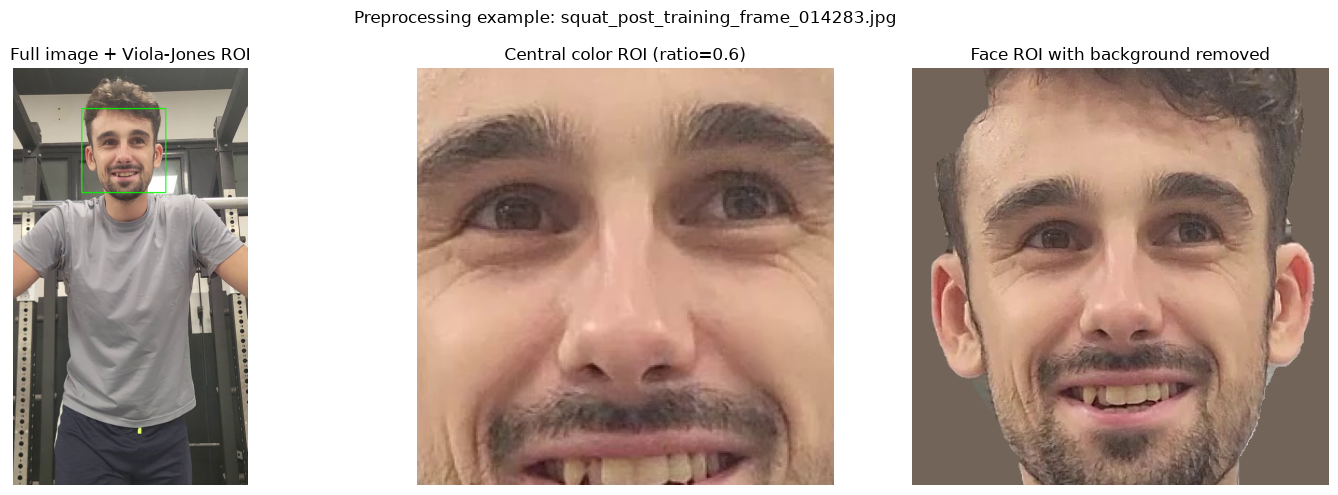

In [59]:
# One reproducible usable test image for the preprocessing visualisation.
_example_path = None
_example_img = None
_example_bbox = None
for _path in np.random.default_rng(SEED+12).permutation(test["chemin"].to_numpy()):
    _img = cv2.imread(str(_path))
    if _img is None:
        continue
    _bbox = detect_face(_img)
    if _bbox is not None:
        _example_path, _example_img, _example_bbox = _path, _img, _bbox
        break
if _example_img is None:
    raise RuntimeError("No test image with a detected face was found for visualisation")
_example_face = reframe(_example_img, _example_bbox, roi_ratio=1.0)
_example_face_without_background = remove_background(_example_face)
_example_color_roi = reframe(_example_img, _example_bbox, roi_ratio=ROI_RATIO)
_example_full_view = _example_img.copy()
_ex, _ey, _ew, _eh = _example_bbox
cv2.rectangle(_example_full_view, (_ex, _ey), (_ex + _ew, _ey + _eh), (0, 255, 0), 3)
fig, axes = plt.subplots(1, 3, figsize=(15, 5))
axes[0].imshow(cv2.cvtColor(_example_full_view, cv2.COLOR_BGR2RGB))
axes[0].set_title("Full image + Viola-Jones ROI")
axes[1].imshow(cv2.cvtColor(_example_color_roi, cv2.COLOR_BGR2RGB))
axes[1].set_title(f"Central color ROI (ratio={ROI_RATIO})")
axes[2].imshow(cv2.cvtColor(_example_face_without_background, cv2.COLOR_BGR2RGB))
axes[2].set_title("Face ROI with background removed")
for ax in axes:
    ax.axis("off")
fig.suptitle(f"Preprocessing example: {Path(_example_path).name}")
plt.tight_layout()
plt.show()

### 2.7 Visual example: geometric feature measurements

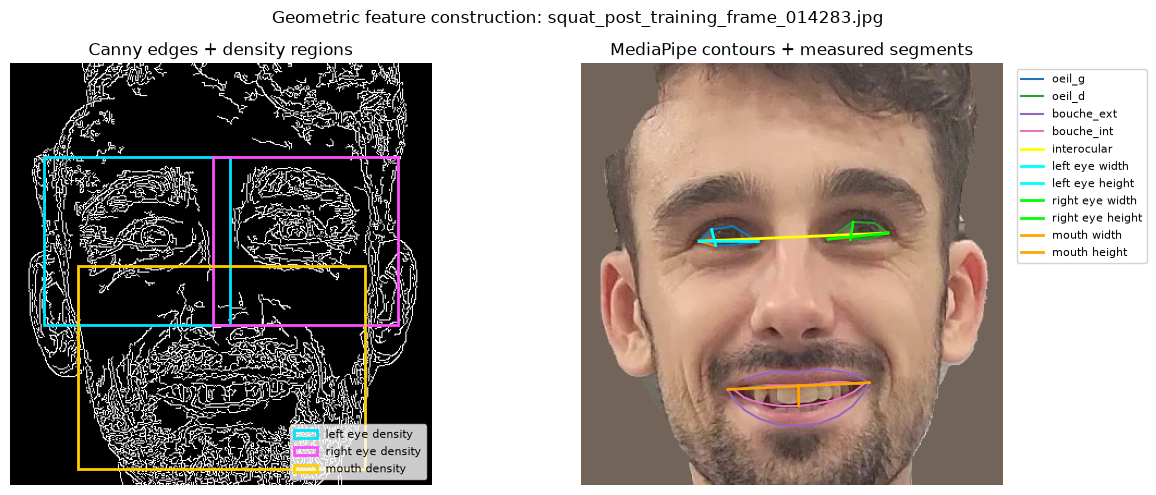

In [60]:
# The same test example, with the exact edge-density regions and landmark segments.
_example_gray = cv2.cvtColor(_example_face_without_background, cv2.COLOR_BGR2GRAY)
_example_edges = cv2.Canny(_example_gray, 30, 100)
_example_h, _example_w = _example_gray.shape
_edge_regions = {
    "left eye density": (0.08, 0.22, 0.52, 0.62, "#00E5FF"),
    "right eye density": (0.48, 0.22, 0.92, 0.62, "#FF4DFF"),
    "mouth density": (0.16, 0.48, 0.84, 0.96, "#FFD000"),
}
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
axes[0].imshow(_example_edges, cmap="gray")
for _label, (_x0, _y0, _x1, _y1, _color) in _edge_regions.items():
    _rect = plt.Rectangle((_x0 * _example_w, _y0 * _example_h),
                          (_x1 - _x0) * _example_w, (_y1 - _y0) * _example_h,
                          fill=False, linewidth=2, label=_label, color=_color)
    axes[0].add_patch(_rect)
axes[0].set_title("Canny edges + density regions")
axes[0].legend(fontsize=8, loc="lower right")
axes[0].axis("off")
axes[1].imshow(cv2.cvtColor(_example_face_without_background, cv2.COLOR_BGR2RGB))
_example_points = _points_landmarks(_example_face_without_background)
if _example_points is None:
    raise RuntimeError("MediaPipe landmarks unavailable for geometric visualisation")
_contour_handles = []
for _name, _indices in _GROUPES_LANDMARKS.items():
    _polygon = np.rint(_example_points[np.asarray(_indices, dtype=int)]).astype(np.int32).reshape(-1, 1, 2)
    _contour_handles.append(axes[1].plot(_polygon[:, 0, 0], _polygon[:, 0, 1], linewidth=1.5, label=_name)[0])
    axes[1].plot([_polygon[-1, 0, 0], _polygon[0, 0, 0]],
                 [_polygon[-1, 0, 1], _polygon[0, 0, 1]], linewidth=1.5)
_measurements = {
    "interocular": (33, 263, "yellow"),
    "left eye width": (33, 133, "cyan"),
    "left eye height": (160, 144, "cyan"),
    "right eye width": (362, 263, "lime"),
    "right eye height": (385, 380, "lime"),
    "mouth width": (61, 291, "orange"),
    "mouth height": (13, 14, "orange"),
}
_measurement_handles = []
for _label, (_a, _b, _color) in _measurements.items():
    _pa, _pb = _example_points[_a], _example_points[_b]
    _measurement_handles.append(axes[1].plot([_pa[0], _pb[0]], [_pa[1], _pb[1]],
        color=_color, linewidth=2, label=_label)[0])
axes[1].set_title("MediaPipe contours + measured segments")
axes[1].legend(handles=_contour_handles + _measurement_handles,
               bbox_to_anchor=(1.02, 1), loc="upper left", fontsize=8, framealpha=0.85)
axes[1].axis("off")
fig.suptitle(f"Geometric feature construction: {Path(_example_path).name}")
fig.subplots_adjust(right=0.76)
plt.tight_layout()
plt.show()

## 3 - Model

In [61]:
# Compare both complete pipelines, then rank every fusion feature with one RF.
JEUX_FEATURES = {
    "Colorimetry (all face ROI)": COLOR_FEATURES,
    "Geometry (all)": GEOMETRY_FEATURES,
    "Fusion (all features)": FEATURES
}

manquantes = [f for f in FEATURES if f not in data.columns]
assert not manquantes, f"Missing features in the dataset: {manquantes}"



def create_models():
    """Create new models at each call (no shared state between feature sets)."""
    return {
        "Baseline (majority class)": DummyClassifier(strategy="most_frequent"),
        "Logistic Regression": make_pipeline(
            StandardScaler(), LogisticRegression(max_iter=2000, class_weight="balanced", random_state=SEED)),
        "Random Forest": RandomForestClassifier(
            n_estimators=300, class_weight="balanced", random_state=SEED, n_jobs=-1),
    }

FINAL_MODEL = "Random Forest"   # Selected interpretable model for the fusion

## 4 - Training and Test for Feature Selection

jeu_features,Colorimetry (all face ROI),Fusion (all features),Geometry (all)
modele,,,
Baseline (majority class),0.333,0.333,0.333
Logistic Regression,0.892,0.956,0.926
Random Forest,0.970,0.986,0.949


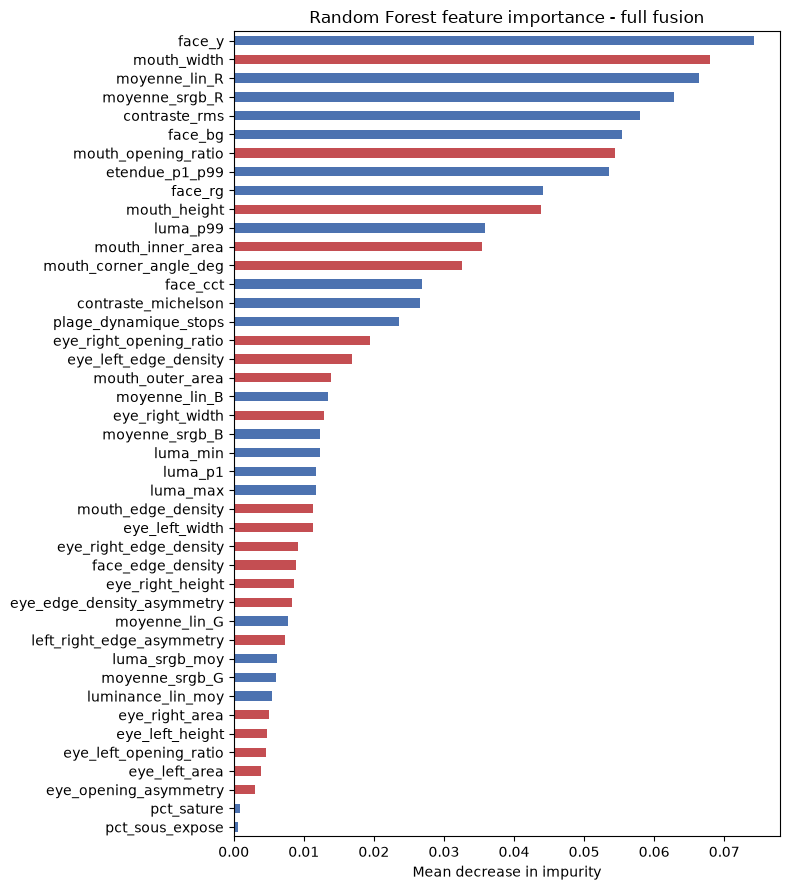

Full-feature fusion model (test set)
Accuracy: 0.979
Balanced accuracy: 0.979


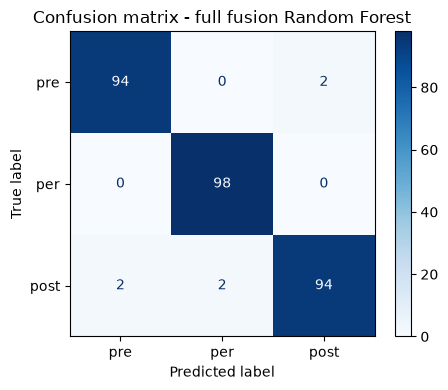

,n_features,features,accuracy_test,balanced_accuracy_test
0,10,"face_y, mouth_width, moyenne_lin_R, moyenne_sr...",0.972603,0.972577
1,5,"face_y, mouth_width, moyenne_lin_R, moyenne_sr...",0.917808,0.918084
2,3,"face_y, mouth_width, moyenne_lin_R",0.907534,0.907809
3,2,"face_y, mouth_width",0.845890,0.846301
4,1,face_y,0.695205,0.695224


In [ ]:
d_train, d_val, d_test = (data[data["jeu"] == j] for j in ("train", "val", "test"))
y_train, y_val, y_test = d_train["condition"], d_val["condition"], d_test["condition"]

# Keep the separated colorimetry/geometry comparison, using every eligible feature.
lignes = []
for nom_jeu, feats in JEUX_FEATURES.items():
    for nom_modele, modele in create_models().items():
        modele.fit(d_train[feats], y_train)
        pred = modele.predict(d_val[feats])
        lignes.append({"jeu_features": nom_jeu, "modele": nom_modele,
                       "accuracy_val": accuracy_score(y_val, pred),
                       "balanced_acc_val": balanced_accuracy_score(y_val, pred)})
scores_val = pd.DataFrame(lignes)
display(scores_val.pivot(index="modele", columns="jeu_features", values="balanced_acc_val").round(3))

# Rank all fusion features on train only, then evaluate fixed top-k subsets on test.
X_trainval = pd.concat([d_train, d_val])
y_trainval = pd.concat([y_train, y_val])
full_model = create_models()[FINAL_MODEL]
full_model.fit(X_trainval[FEATURES], y_trainval)
fusion_ranker = full_model
importance = pd.Series(full_model.feature_importances_, index=FEATURES).sort_values(ascending=False)

# Diagnostics for the complete fusion model, before feature reduction.
importance_plot = importance.sort_values()
importance_colors = ["#4C72B0" if SOURCE[f] == "colorimetry" else "#C44E52" for f in importance_plot.index]
fig, ax = plt.subplots(figsize=(8, 9))
importance_plot.plot.barh(ax=ax, color=importance_colors)
ax.set_title("Random Forest feature importance - full fusion")
ax.set_xlabel("Mean decrease in impurity")
plt.tight_layout()
plt.savefig("figures/rf_feature_importance_fusion_full.png", dpi=150, bbox_inches="tight")
plt.show()

full_pred = full_model.predict(d_test[FEATURES])
print("Full-feature fusion model (test set)")
print(f"Accuracy: {accuracy_score(y_test, full_pred):.3f}")
print(f"Balanced accuracy: {balanced_accuracy_score(y_test, full_pred):.3f}")
fig, ax = plt.subplots(figsize=(5, 4))
ConfusionMatrixDisplay.from_predictions(y_test, full_pred, labels=CONDITIONS, cmap="Blues", ax=ax)
ax.set_title("Confusion matrix - full fusion Random Forest")
plt.tight_layout()
plt.savefig("figures/confusion_rf_fusion_full.png", dpi=150, bbox_inches="tight")
plt.show()

TOP_K = [10, 5, 3, 2, 1]
top_features = {k: importance.head(k).index.tolist() for k in TOP_K}
selection_results, selected_models = [], {}
for k in TOP_K:
    feats = top_features[k]
    model = create_models()[FINAL_MODEL]
    model.fit(X_trainval[feats], y_trainval)
    selected_models[k] = model
    pred = model.predict(d_test[feats])
    selection_results.append({"n_features": k, "features": ", ".join(feats),
                              "accuracy_test": accuracy_score(y_test, pred),
                              "balanced_accuracy_test": balanced_accuracy_score(y_test, pred)})
selection_results = pd.DataFrame(selection_results)
display(selection_results)
final_models = {}
for nom_jeu, feats in JEUX_FEATURES.items():
    model = create_models()[FINAL_MODEL]
    model.fit(X_trainval[feats], y_trainval)
    final_models[nom_jeu] = model
final_models["Fusion (all features)"] = full_model

## 5. Temporal Dataset Statistical Analyses According to Selected Features

In [63]:
# Choice: top 3 features
TOP3 = top_features[3]

print(f"Selected top 3 features for statistical analyses: {TOP3}")

Selected top 3 features for statistical analyses: ['face_y', 'mouth_width', 'moyenne_lin_R']


### 5.1 Top-3 features extraction

In [64]:
# Compute features on the temporal analysis dataset, using the same extraction pipeline as before.
temporal_dataset = pd.DataFrame([
    {"chemin": str(c), "condition": g, "sujet": s}
    for g in CONDITIONS for s in SUBJECTS for c in sorted((FOLDER_TEMPORAL_ANALYSIS / f"squat_{g}_{s}").glob("*.jpg"))
])

print(temporal_dataset.head())

# Extraction function only for the top features
def extract_top_features(chemin, top_feats):
    """Input: image path + list of features. Output: dict {top features}, or None if extraction fails."""
    feats = extract_features(chemin)
    if feats is None:
        return None
    return {f: feats[f] for f in top_feats}

# Top features extraction of the temporal dataset
lignes, ecartees = [], 0
for ligne in temporal_dataset.itertuples(index=False):
    feats = extract_top_features(ligne.chemin, top_feats=TOP3) 
    if feats is None:
        ecartees += 1
        continue
    lignes.append({"chemin": ligne.chemin, "condition": ligne.condition, "sujet": ligne.sujet, **feats})

data_temporal = pd.DataFrame(lignes)
data_temporal.to_csv("features_temporal.csv", index=False)

print(f"{len(data_temporal)} usable images, {ecartees} discarded (no face or no landmarks)")
print(data_temporal.head())

                                              chemin condition sujet
0  data\dataset_squat_temporal_analysis\squat_pre...       pre  joel
1  data\dataset_squat_temporal_analysis\squat_pre...       pre  joel
2  data\dataset_squat_temporal_analysis\squat_pre...       pre  joel
3  data\dataset_squat_temporal_analysis\squat_pre...       pre  joel
4  data\dataset_squat_temporal_analysis\squat_pre...       pre  joel
2193 usable images, 25 discarded (no face or no landmarks)
                                              chemin condition sujet  \
0  data\dataset_squat_temporal_analysis\squat_pre...       pre  joel   
1  data\dataset_squat_temporal_analysis\squat_pre...       pre  joel   
2  data\dataset_squat_temporal_analysis\squat_pre...       pre  joel   
3  data\dataset_squat_temporal_analysis\squat_pre...       pre  joel   
4  data\dataset_squat_temporal_analysis\squat_pre...       pre  joel   

     face_y  mouth_width  moyenne_lin_R  
0  0.346216     0.584181       0.485125  
1  0.34637

### 5.2 Between-condition and subject analysis of central tendency

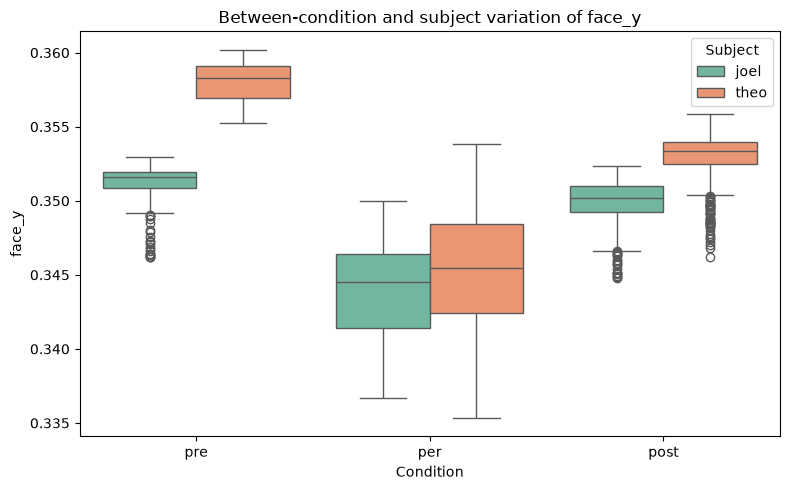

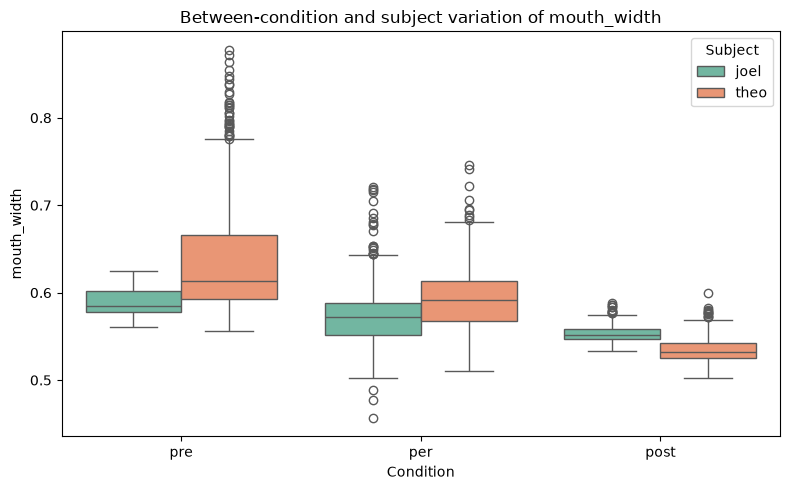

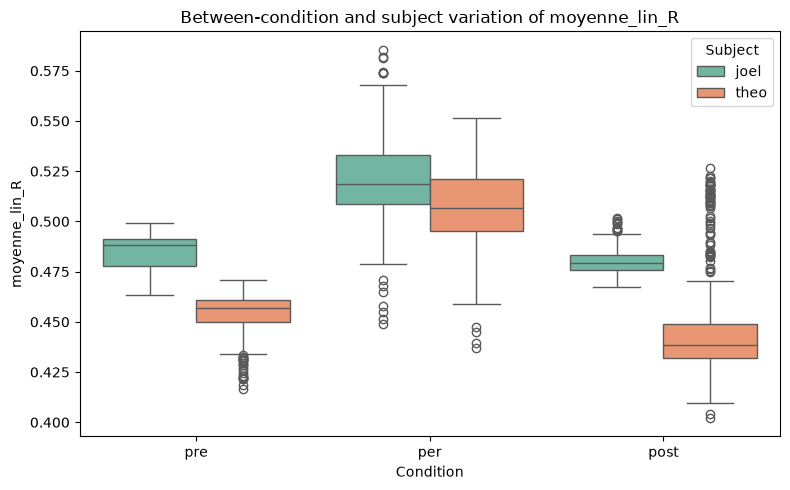

In [72]:
# Boxplots of the top 3 features over time for each subject and group
for feat in TOP3:
    plt.figure(figsize=(8, 5))
    sns.boxplot(x="condition", y=feat, hue="sujet", data=data_temporal, palette="Set2")
    plt.title(f"Between-condition and subject variation of {feat}")
    plt.xlabel("Condition")
    plt.ylabel(feat)
    plt.legend(title="Subject")
    plt.tight_layout()
    plt.savefig(f"figures/temporal_{feat}.png", dpi=150, bbox_inches="tight")
    plt.show()
    

In [73]:
# Statistical analysis: ANOVA for each top feature with respect to group and subject
for feat in TOP3:
    model = ols(f"{feat} ~ condition * sujet", data=data_temporal).fit()
    print(f"ANOVA for {feat}:")
    print(sm.stats.anova_lm(model, typ=2))
    print()


ANOVA for face_y:
                   sum_sq      df            F         PR(>F)
condition        0.033158     2.0  3059.549520   0.000000e+00
sujet            0.008620     1.0  1590.712250  6.988473e-262
condition:sujet  0.002686     2.0   247.831198   9.720744e-98
Residual         0.011851  2187.0          NaN            NaN

ANOVA for mouth_width:
                   sum_sq      df           F         PR(>F)
condition        2.073409     2.0  748.040265  2.969484e-248
sujet            0.195459     1.0  141.034580   1.443710e-31
condition:sujet  0.529861     2.0  191.162182   3.073537e-77
Residual         3.030950  2187.0         NaN            NaN

ANOVA for moyenne_lin_R:
                   sum_sq      df            F         PR(>F)
condition        0.956719     2.0  1679.635130   0.000000e+00
sujet            0.393798     1.0  1382.717707  5.716189e-235
condition:sujet  0.036063     2.0    63.312273   1.863702e-27
Residual         0.622857  2187.0          NaN            NaN



Everything is significant, which is not a big surprise: we have many data points and means are obviously different between conditions, between individuals and in the interaction of both.

### 5.3 Temporal analysis

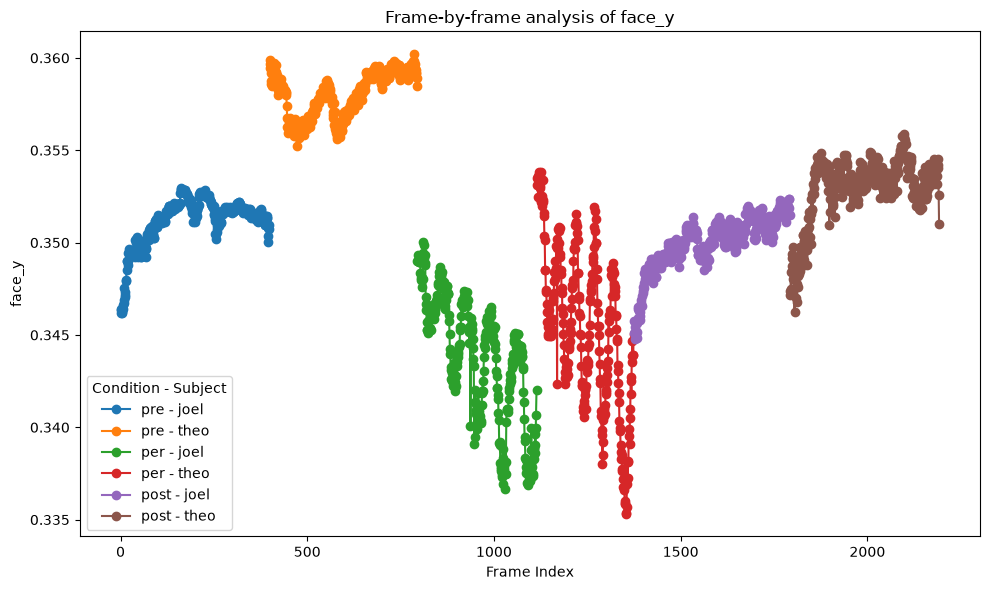

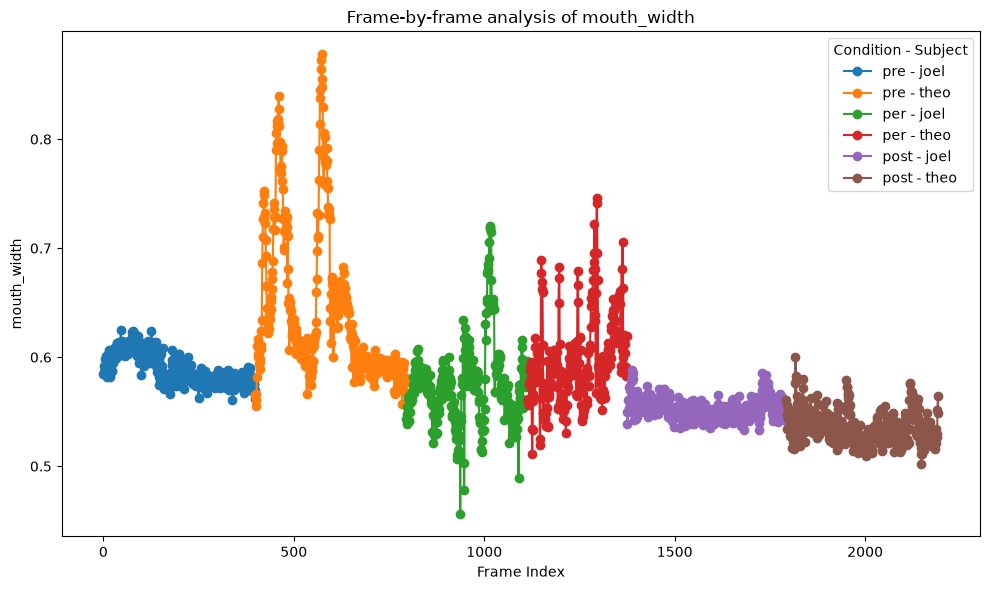

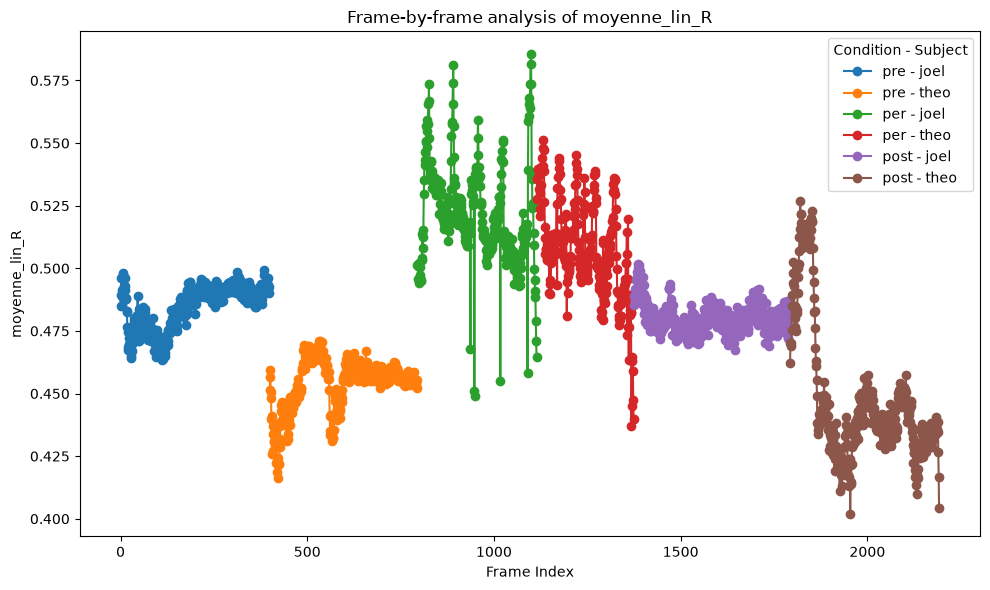

In [74]:
# Plot frame-by-frame the top 3 features in 3 figures over time for each condition with the two subjects in the same graph
for feat in TOP3:
    plt.figure(figsize=(10, 6))
    for g in CONDITIONS:
        subset = data_temporal[data_temporal["condition"] == g]
        for s in SUBJECTS:
            subject_subset = subset[subset["sujet"] == s]
            plt.plot(subject_subset.index, subject_subset[feat], marker='o', label=f"{g} - {s}")
    plt.title(f"Frame-by-frame analysis of {feat}")
    plt.xlabel("Frame Index")
    plt.ylabel(feat)
    plt.legend(title="Condition - Subject")
    plt.tight_layout()
    plt.savefig(f"figures/frame_by_frame_{feat}.png", dpi=150, bbox_inches="tight")
    plt.show()

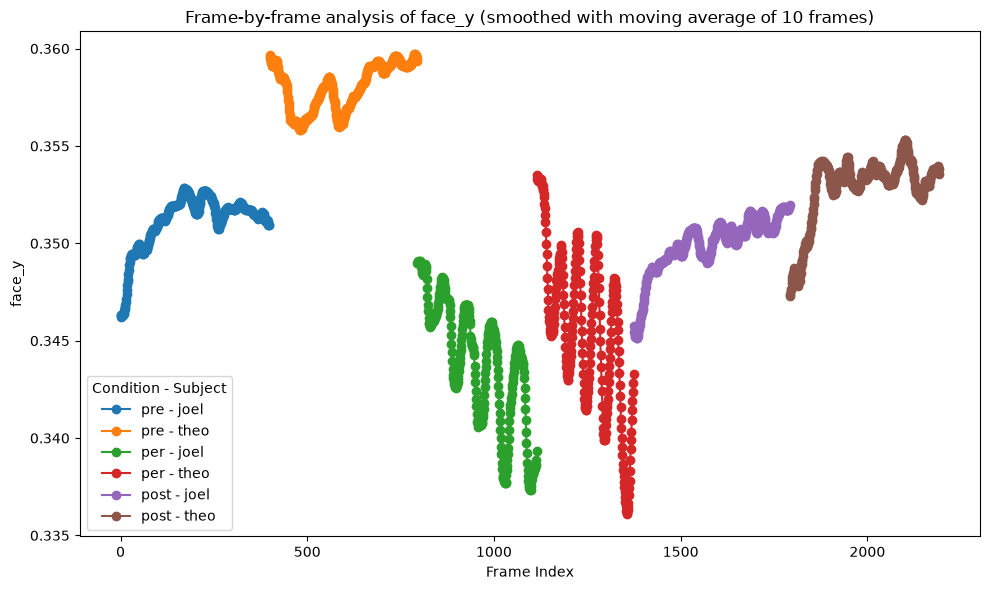

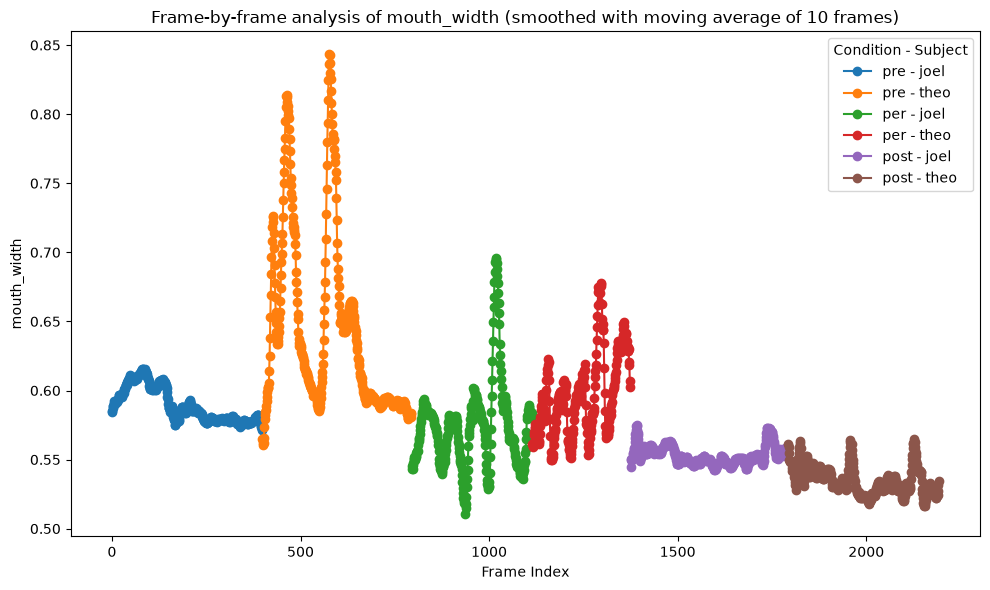

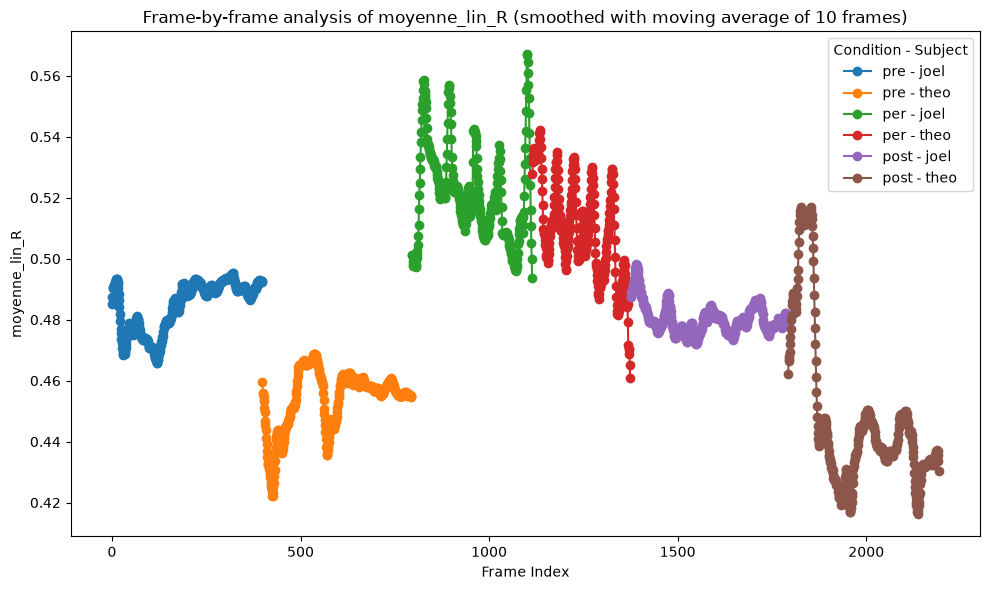

In [76]:
# The same with a moving average (window=10) to smooth the curves
for feat in TOP3:
    plt.figure(figsize=(10, 6))
    for g in CONDITIONS:
        subset = data_temporal[data_temporal["condition"] == g]
        for s in SUBJECTS:
            subject_subset = subset[subset["sujet"] == s]
            smoothed = subject_subset[feat].rolling(window=10, min_periods=1).mean()
            plt.plot(subject_subset.index, smoothed, marker='o', label=f"{g} - {s}")
    plt.title(f"Frame-by-frame analysis of {feat} (smoothed with moving average of 10 frames)")
    plt.xlabel("Frame Index")
    plt.ylabel(feat)
    plt.legend(title="Condition - Subject")
    plt.tight_layout()
    plt.savefig(f"figures/frame_by_frame_smoothed_{feat}.png", dpi=150, bbox_inches="tight")
    plt.show()

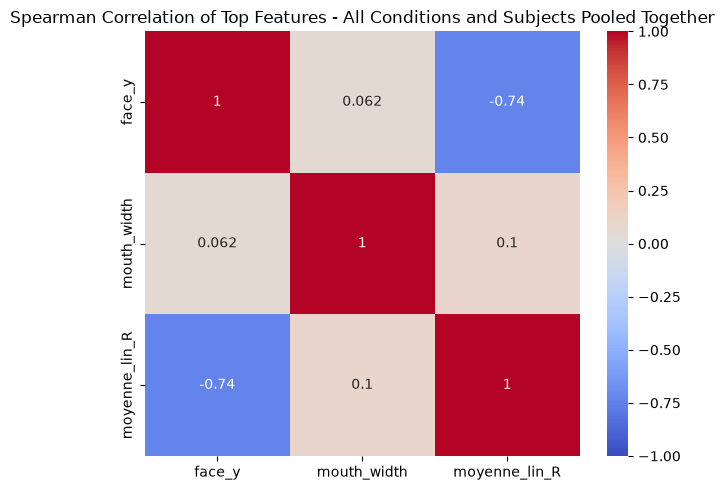

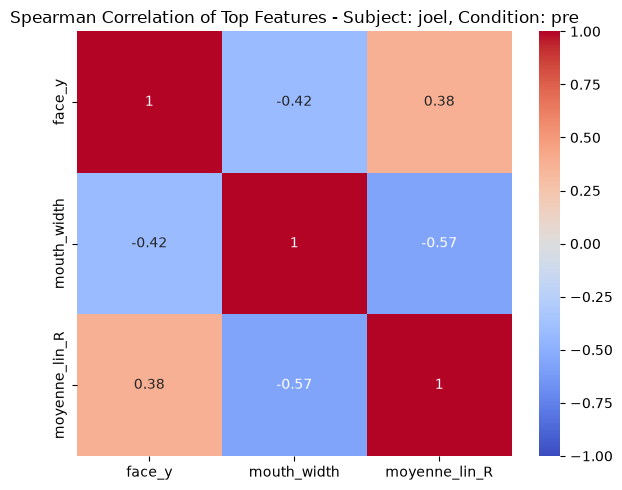

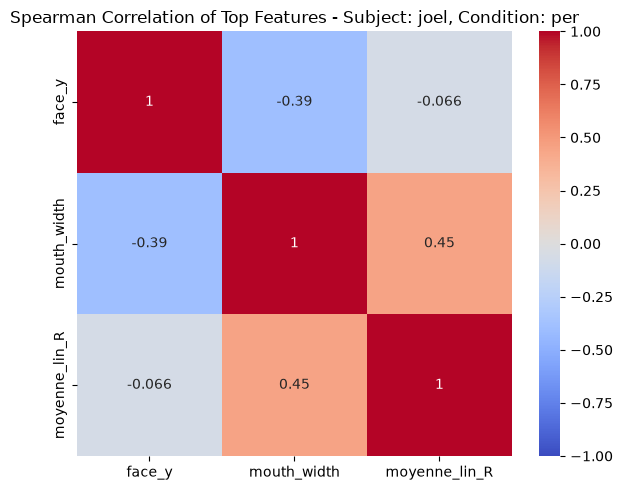

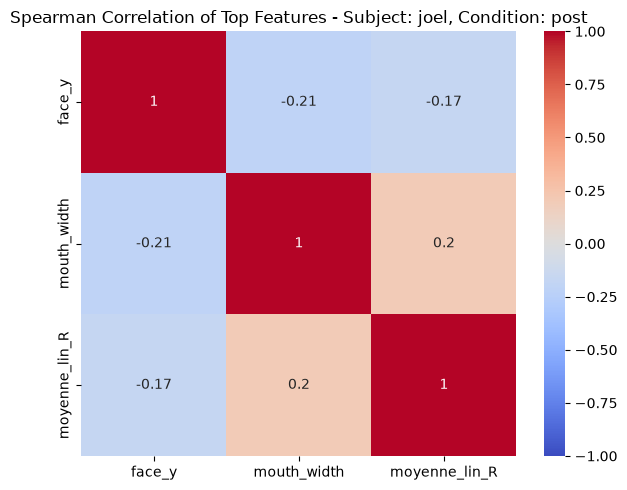

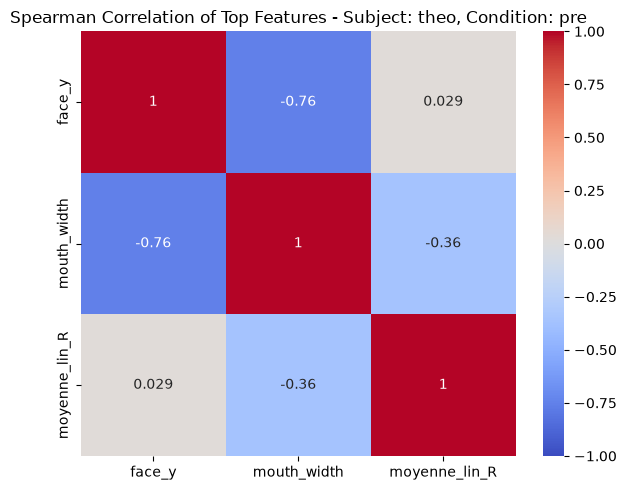

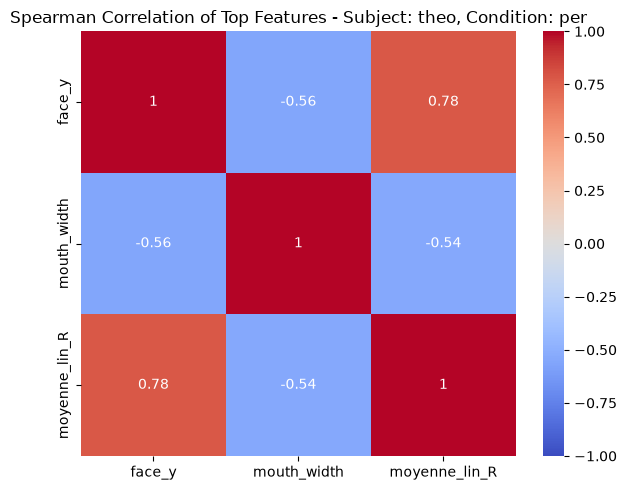

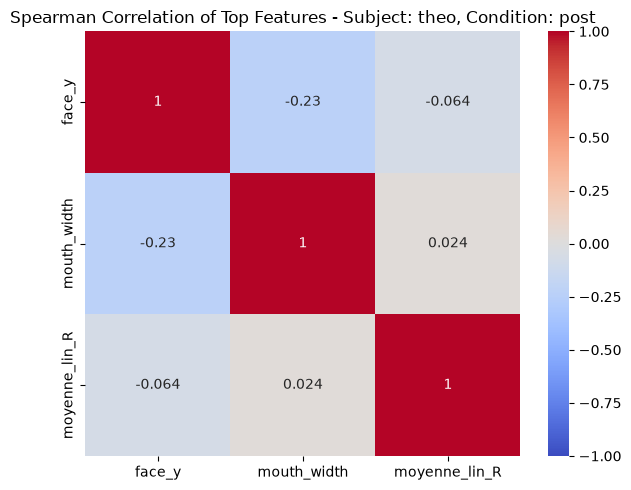

In [77]:
# Spearman cross-correlation between the top 3 features across all conditions and all subjects
all_data = data_temporal[TOP3]
corr_matrix = all_data.corr(method='spearman')
plt.figure(figsize=(6, 5))
sns.heatmap(corr_matrix, annot=True, cmap="coolwarm", vmin=-1, vmax=1)
plt.title("Spearman Correlation of Top Features - All Conditions and Subjects Pooled Together")
plt.tight_layout()
plt.savefig("figures/spearman_correlation_all.png", dpi=150, bbox_inches="tight")
plt.show()

# Spearman cross-correlation between the top 3 features for each subject and condition
for s in SUBJECTS:
    for g in CONDITIONS:
        subset = data_temporal[(data_temporal["sujet"] == s) & (data_temporal["condition"] == g)]
        if len(subset) < 2:
            print(f"Not enough data for subject {s} and condition {g} to compute correlation.")
            continue
        corr_matrix = subset[TOP3].corr(method='spearman')
        plt.figure(figsize=(6, 5))
        sns.heatmap(corr_matrix, annot=True, cmap="coolwarm", vmin=-1, vmax=1)
        plt.title(f"Spearman Correlation of Top Features - Subject: {s}, Condition: {g}")
        plt.tight_layout()
        plt.savefig(f"figures/spearman_correlation_{s}_{g}.png", dpi=150, bbox_inches="tight")
        plt.show()


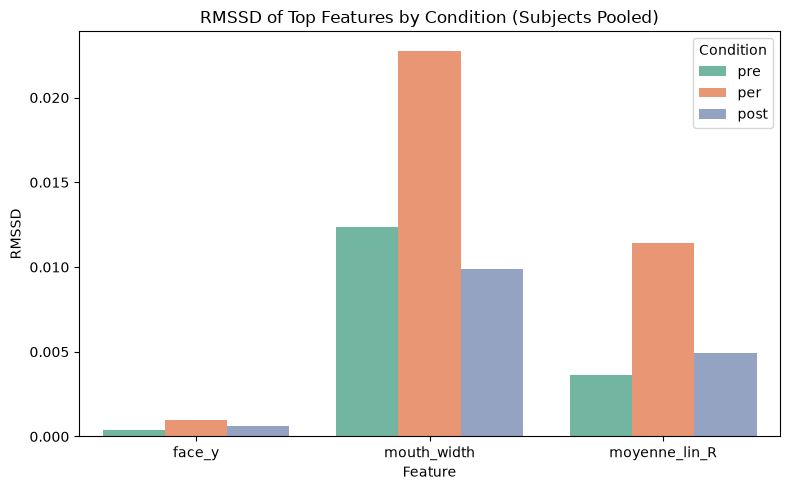

In [79]:
# RMSSD (Root Mean Square of Successive Differences) for each top feature and condition, subject pooled
rmssd_results = []
for feat in TOP3:
    for g in CONDITIONS:
        subset = data_temporal[data_temporal["condition"] == g]
        diffs = subset[feat].diff().dropna()
        rmssd = np.sqrt(np.mean(diffs ** 2))
        rmssd_results.append({"feature": feat, "condition": g, "rmssd": rmssd})

rmssd_df = pd.DataFrame(rmssd_results)
plt.figure(figsize=(8, 5))
sns.barplot(x="feature", y="rmssd", hue="condition", data=rmssd_df, palette="Set2")
plt.title("RMSSD of Top Features by Condition (Subjects Pooled)")
plt.xlabel("Feature")
plt.ylabel("RMSSD")
plt.legend(title="Condition")
plt.tight_layout()
plt.savefig("figures/rmssd_top_features.png", dpi=150, bbox_inches="tight")
plt.show()

## 6. Discussion

These analyses show in the squat exercise several key facial markers of effort: face brightness, the distance between mouth corners and the level of red. We can have interpretations for each of these features. Luminance can be related to sweat production, mouth width to the breathing technique of the squat, and level of red to the increase in blood flux. 

What is cunning is that even though the figures showing the level of these variables during effort is highly variable, the Random Forest still manages to get 90 % of accuracy only with those three. This suggests that there exists non-linear relationships between these variables in our conditions. Indeed, Spearman correlations do show very different trends according to the condition and subject. 

The temporal representations of brightness, mouth width and red intensity allow us to say that these variables evolute in time in all three situations, but highly depend on each repetition during effort. A decreasing trend can be seen for the colorimetric features, while an increasing one can be seen for the morphological/behavioural feature. However, we clearly distinguish the effect of each of the squat repetitions, that strongly decrease the colorimetric features and moderately increase mouth width during execution, while inter-repetition recovery allows features to almost come back to the original values. 

These observations more broadly support the interest of computer vision for fatigue detection or intensity measurement. It can be seen that a few facial features and poor training can result in excellent accuracy of effort or exercise phase detection. Moreover, the level of these variables vary very quickly in powerlifting movements, which can be interesting for live intensity monitoring.